# 05 · Updating a fitted model

`model.update(new_rows)` folds new data into a fitted network without the old
data and without retraining from scratch.  We stream batches from a known
ground truth, compare `update` with refitting on everything seen so far, look
at what each mechanism does during an update, show that a failed update leaves
the model untouched, and track a change of regime with forgetting.

- **NBN API:** `fit`, `update` (with `forgetting=`), `UpdateHistory`
  (`node_methods`, `skipped`, `node_log_likelihoods`, `wall_clock_s`), and the
  update paths of `CategoricalTableMechanism` (Dirichlet counts),
  `LinearGaussianMechanism` (recursive least squares), `MDNMechanism` /
  `NeuralCategoricalMechanism` (online Laplace / EWC).
- **Runtime:** about 15 s on a laptop CPU.
- **Install:** `pip install "nbn[examples]"`, then `jupyter lab examples/`.
- **Device:** CUDA or Apple MPS when available, else the CPU (set `NBN_EXAMPLES_DEVICE=cpu` to force the CPU).

Ground truth (hidden from the learner):

    Rain       ~ Bernoulli(0.3)
    Sprinkler  | Rain             table
    WetGrass   | Rain, Sprinkler  table
    Soil       = -1 + 2.5 WetGrass + N(0, 0.5^2)
    Growth     = 0.8 Soil + 0.5 + N(0, 0.3^2)

Every node is a table or a linear-Gaussian model, so the KL divergence between
the true and the learned network can be computed exactly.

In [1]:
import copy
import itertools
import math
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import torch

from nbn import (
    CategoricalTableMechanism,
    LinearGaussianMechanism,
    MDNMechanism,
    NeuralBayesianNetwork,
    NeuralCategoricalMechanism,
    UpdateHistory,
    seed_all,
)
from nbn.utils.device import resolve_device
from _figures import BLUE, ORANGE, AQUA, VERMILLION, SKY, MAGENTA, YELLOW, GREY, INK, DOUBLE, SINGLE, save, use_style

use_style()  # one style for every example: palette, sizes, fonts (_figures.py)

# "auto" picks CUDA, then Apple MPS, then the CPU.  The stored outputs were made
# with NBN_EXAMPLES_DEVICE=cpu; on an accelerator the last digits can differ.
device = resolve_device(os.environ.get("NBN_EXAMPLES_DEVICE", "auto"))
print("device:", device)



def to_numpy(t: torch.Tensor):
    """Move to the CPU first, then convert: tensors on MPS / CUDA cannot go to numpy directly."""
    return t.detach().cpu().numpy()

device: cpu


## The ground truth

`sample(n, ...)` draws rows; the sprinkler table and the `Growth` slope are
arguments, so that section 5 can change them.  `exact_kl(model)` computes
`KL(true || learned)` of the whole network in closed form: the three tables by
enumerating their 8 joint states, the two linear-Gaussian nodes from the
Gaussian KL formula averaged over their parent.  The data stay on the CPU; the
model moves them to its own device.

In [2]:
P_RAIN = torch.tensor([0.7, 0.3])
P_SPRINKLER = torch.tensor([[0.5, 0.5], [0.9, 0.1]])                      # [rain, sprinkler]
P_WET = torch.tensor([[[0.95, 0.05], [0.20, 0.80]],                       # [rain, sprinkler, wet]
                      [[0.15, 0.85], [0.02, 0.98]]])
SOIL_SD, GROWTH_SD = 0.5, 0.3
EDGES = [("Rain", "Sprinkler"), ("Rain", "WetGrass"), ("Sprinkler", "WetGrass"),
         ("WetGrass", "Soil"), ("Soil", "Growth")]
VARIABLES = {"Rain": ("discrete", 2), "Sprinkler": ("discrete", 2), "WetGrass": ("discrete", 2),
             "Soil": ("continuous", 1), "Growth": ("continuous", 1)}


def sample(n: int, p_sprinkler=P_SPRINKLER, slope: float = 0.8) -> dict:
    rain = torch.multinomial(P_RAIN, n, replacement=True)
    sprinkler = torch.bernoulli(p_sprinkler[rain, 1]).long()
    wet = torch.bernoulli(P_WET[rain, sprinkler, 1]).long()
    soil = -1.0 + 2.5 * wet + SOIL_SD * torch.randn(n)
    growth = slope * soil + 0.5 + GROWTH_SD * torch.randn(n)
    return {"Rain": rain, "Sprinkler": sprinkler, "WetGrass": wet,
            "Soil": soil[:, None], "Growth": growth[:, None]}


ENUM = {k: torch.tensor(v) for k, v in zip(("Rain", "Sprinkler", "WetGrass"),
                                          zip(*itertools.product((0, 1), repeat=3)))}


def gauss_kl(m1, s1, m2, s2):
    """KL(N(m1, s1^2) || N(m2, s2^2))."""
    return math.log(s2 / s1) + (s1 ** 2 + (m1 - m2) ** 2) / (2 * s2 ** 2) - 0.5


def exact_kl(model, p_sprinkler=P_SPRINKLER, slope: float = 0.8) -> float:
    r, s, w = ENUM["Rain"], ENUM["Sprinkler"], ENUM["WetGrass"]
    p_true = P_RAIN[r] * p_sprinkler[r, s] * P_WET[r, s, w]
    rows = dict(ENUM, Soil=torch.zeros(8, 1), Growth=torch.zeros(8, 1))  # dummy continuous values
    with torch.no_grad():
        lp = model.log_prob(rows, per_node=True)
        q = (lp["Rain"] + lp["Sprinkler"] + lp["WetGrass"]).exp().cpu()
        kl = float((p_true * (p_true.log() - q.log())).sum())
        # Soil | WetGrass: one Gaussian per parent value, weighted by the true P(WetGrass).
        soil = model.mechanisms["Soil"](torch.tensor([[0.0], [1.0]], device=model.device))
        loc, sd = to_numpy(soil.mean).ravel(), to_numpy(soil.stddev).ravel()
        p_wet = float(p_true[w == 1].sum())
        for wet, pw in ((0, 1 - p_wet), (1, p_wet)):
            kl += pw * gauss_kl(-1.0 + 2.5 * wet, SOIL_SD, loc[wet], sd[wet])
        # Growth | Soil: learned N(a Soil + b, sd^2); average the KL over the true law of Soil.
        g = model.mechanisms["Growth"](torch.tensor([[0.0], [1.0]], device=model.device))
        g_loc, g_sd = to_numpy(g.mean).ravel(), float(to_numpy(g.stddev).ravel()[0])
        a, b = g_loc[1] - g_loc[0], g_loc[0]
        mean_s = p_wet * 1.5 + (1 - p_wet) * -1.0
        second_s = SOIL_SD ** 2 + p_wet * 1.5 ** 2 + (1 - p_wet) * 1.0
        # E[((slope - a) S + (0.5 - b))^2] over S
        mse = (slope - a) ** 2 * second_s + 2 * (slope - a) * (0.5 - b) * mean_s + (0.5 - b) ** 2
        kl += math.log(g_sd / GROWTH_SD) + (GROWTH_SD ** 2 + mse) / (2 * g_sd ** 2) - 0.5
    return kl


def build() -> NeuralBayesianNetwork:
    model = NeuralBayesianNetwork(EDGES, VARIABLES, device=device)
    for node in ("Rain", "Sprinkler", "WetGrass"):
        model.set_mechanism(node, CategoricalTableMechanism())
    for node in ("Soil", "Growth"):
        model.set_mechanism(node, LinearGaussianMechanism())
    return model

## 1. Streaming batches: `update` against refitting

We fit on a first batch of 5000 rows, then receive 19 more batches of 5000.
After each batch we either call `update(batch)` (the model never sees the old
rows again) or refit a fresh model on all rows seen so far.  We record the
exact KL to the truth and the time of each step (the best of 3 runs, to reduce
timer noise).

In [3]:
BATCH, N_BATCHES = 5000, 20
seed_all(1)
batches = [sample(BATCH) for _ in range(N_BATCHES)]

streamed = build()
streamed.fit(batches[0])
rows_seen, kl_update, kl_refit, t_update, t_refit = [BATCH], [exact_kl(streamed)], [], [], []
kl_refit.append(kl_update[0])
for i in range(1, N_BATCHES):
    times = []
    for _ in range(3):
        trial = copy.deepcopy(streamed)
        start = time.perf_counter()
        history = trial.update(batches[i])
        times.append(time.perf_counter() - start)
    streamed = trial
    t_update.append(min(times))

    pooled = {k: torch.cat([b[k] for b in batches[:i + 1]]) for k in batches[0]}
    times = []
    for _ in range(3):
        refit = build()
        start = time.perf_counter()
        refit.fit(pooled)
        times.append(time.perf_counter() - start)
    t_refit.append(min(times))
    rows_seen.append(BATCH * (i + 1))
    kl_update.append(exact_kl(streamed))
    kl_refit.append(exact_kl(refit))

with torch.no_grad():
    check = sample(2000)
    gap = (streamed.log_prob(check) - refit.log_prob(check)).abs().max()
print(f"after {rows_seen[-1]} rows: KL update {kl_update[-1]:.2e}, KL refit {kl_refit[-1]:.2e}")
print(f"largest |log p_update - log p_refit| over 2000 rows: {float(gap):.1e}")
print(f"time per step: update {1e3 * np.mean(t_update):.2f} ms on average; "
      f"refit {1e3 * t_refit[0]:.2f} ms at {rows_seen[1]} rows, {1e3 * t_refit[-1]:.2f} ms at {rows_seen[-1]} rows")

after 100000 rows: KL update 6.51e-05, KL refit 6.51e-05
largest |log p_update - log p_refit| over 2000 rows: 2.8e-05
time per step: update 1.13 ms on average; refit 1.64 ms at 10000 rows, 9.33 ms at 100000 rows


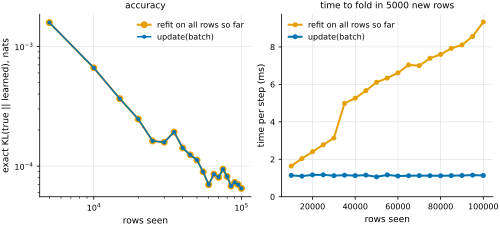

In [4]:
fig, (ax_kl, ax_t) = plt.subplots(1, 2, figsize=(DOUBLE, 3.2))
ax_kl.plot(rows_seen, kl_refit, "o-", color=ORANGE, lw=2, ms=6, label="refit on all rows so far")
ax_kl.plot(rows_seen, kl_update, "o-", color=BLUE, lw=1.5, ms=3, label="update(batch)")
ax_kl.set(xscale="log", yscale="log", xlabel="rows seen", ylabel="exact KL(true || learned), nats",
          title="accuracy")
ax_kl.legend(frameon=False, fontsize=8)
ax_t.plot(rows_seen[1:], 1e3 * np.array(t_refit), "o-", color=ORANGE, lw=2, ms=4,
          label="refit on all rows so far")
ax_t.plot(rows_seen[1:], 1e3 * np.array(t_update), "o-", color=BLUE, lw=2, ms=4,
          label="update(batch)")
ax_t.set(xlabel="rows seen", ylabel="time per step (ms)", ylim=(0, None),
         title=f"time to fold in {BATCH} new rows")
ax_t.legend(frameon=False, fontsize=8, loc="upper left")
save(fig, "05_fig1")      # vector PDF + 300-dpi PNG in examples/figures/
plt.show()

**Figure.** Streaming a table and a linear-Gaussian model in batches: exact KL from the truth after each batch (left, log-log) and the time of one step (right), for `update(batch)` and for a refit on all rows seen so far; one run.

Left: the two curves lie on top of each other.  The table and
linear-Gaussian updates are exact: after 100,000 rows both models have a KL of
6.51e-05, and their log-probabilities differ by at most 2.8e-05 (float32
rounding).  Right: an update costs about the same at every step (about a
millisecond here), because it only reads the new batch.  A refit reads every
row seen so far, and its cost grows with them: several times more at 100,000
rows than at 10,000 (the printed numbers above).  The jump in the refit time
between 30,000 and 35,000 rows came back in every run on this machine; what
matters is the trend.

## 2. What each mechanism does during an update

`update` returns an `UpdateHistory`.  `node_methods` names the update path
each node took; `skipped` lists nodes whose mechanism has no incremental update
(their fitted CPD is kept as it is); `node_log_likelihoods` is the mean
log-likelihood of the new batch after the update.

- `CategoricalTableMechanism` keeps its count table and adds the new counts
  (`dirichlet_conjugate`): exact.
- `LinearGaussianMechanism` keeps the sufficient statistics of its least-squares
  fit and merges the new ones (`recursive_gaussian`): exact.
- `MDNMechanism` and `NeuralCategoricalMechanism` keep their fitted weights and
  a diagonal Fisher information, and train on the new batch with a penalty that
  holds important weights near their old values (`online_ewc`, online Laplace /
  elastic weight consolidation): approximate.
- `BinningCategoricalTable` (what `auto_mechanisms` gives a discrete node with a
  continuous parent) has no update and is skipped.

We add a discrete `Runoff | Soil` node to show the skip.

In [5]:
EDGES_R = EDGES + [("Soil", "Runoff")]
VARIABLES_R = dict(VARIABLES, Runoff=("discrete", 2))


def sample_r(n: int) -> dict:
    rows = sample(n)
    rows["Runoff"] = torch.bernoulli(torch.sigmoid(3.0 * (rows["Soil"][:, 0] - 1.0))).long()
    return rows


seed_all(2)
mixed = NeuralBayesianNetwork(EDGES_R, VARIABLES_R, device=device)
mixed.set_mechanism("WetGrass", NeuralCategoricalMechanism(n_classes=2))
mixed.set_mechanism("Soil", MDNMechanism(num_components=2))
mixed.set_mechanism("Growth", LinearGaussianMechanism())
mixed.auto_mechanisms()             # tables for Rain / Sprinkler, a binning table for Runoff
mixed.fit(sample_r(2000))           # consolidate=True (the default) stores what EWC needs
history = mixed.update(sample_r(1000))
assert isinstance(history, UpdateHistory)
print(f"{'node':10s} {'mechanism':26s} {'update path':22s} new-batch log-lik")
for node in mixed.dag.topological_order():
    method = history.node_methods.get(node, "skipped" if node in history.skipped else "?")
    ll = history.node_log_likelihoods.get(node, float("nan"))
    print(f"{node:10s} {type(mixed.mechanisms[node]).__name__:26s} {method:22s} {ll:8.3f}")
print("skipped:", history.skipped, f"| wall_clock_s = {history.wall_clock_s:.2f} | device = {history.device}")

node       mechanism                  update path            new-batch log-lik
Rain       CategoricalTableMechanism  dirichlet_conjugate      -0.601
Sprinkler  CategoricalTableMechanism  dirichlet_conjugate      -0.570
WetGrass   NeuralCategoricalMechanism online_ewc               -0.390
Soil       MDNMechanism               online_ewc               -0.734
Growth     LinearGaussianMechanism    recursive_gaussian       -0.245
Runoff     BinningCategoricalTable    skipped                     nan
skipped: ['Runoff'] | wall_clock_s = 0.27 | device = cpu


The EWC path is approximate, so we check it against a refit.  An MDN on `Soil`
is fitted on 500 rows and then updated with 7 more batches of 500 rows.  We
compare its held-out log-likelihood with a model that is never updated and with
a refit on all rows so far.

In [6]:
held_out = sample_r(10_000)
true_ll = float(torch.distributions.Normal(-1.0 + 2.5 * held_out["WetGrass"].float(), SOIL_SD)
                .log_prob(held_out["Soil"][:, 0]).mean())


def soil_ll(model) -> float:
    with torch.no_grad():
        return float(model.log_prob(held_out, per_node=True)["Soil"].mean())


def mdn_model() -> NeuralBayesianNetwork:
    model = NeuralBayesianNetwork(EDGES_R, VARIABLES_R, device=device)
    model.set_mechanism("Soil", MDNMechanism(num_components=2))
    model.auto_mechanisms()
    return model


seed_all(3)
small = [sample_r(500) for _ in range(8)]
seed_all(4)
ewc = mdn_model()
ewc.fit(small[0])
frozen_ll = soil_ll(ewc)
ewc_ll, refit_ll, ewc_t, refit_t = [frozen_ll], [frozen_ll], [], []
for i in range(1, len(small)):
    start = time.perf_counter()
    ewc.update(small[i])
    ewc_t.append(time.perf_counter() - start)
    ewc_ll.append(soil_ll(ewc))
    seed_all(5)
    again = mdn_model()
    start = time.perf_counter()
    again.fit({k: torch.cat([b[k] for b in small[:i + 1]]) for k in small[0]})
    refit_t.append(time.perf_counter() - start)
    refit_ll.append(soil_ll(again))
print(f"true model, held-out log-lik of Soil: {true_ll:.4f}")
print(f"after the first 500 rows:          {frozen_ll:.4f}")
print(f"after 4000 rows: EWC update {ewc_ll[-1]:.4f}, refit {refit_ll[-1]:.4f}")
print(f"mean time per step: EWC update {np.mean(ewc_t):.2f} s, refit {np.mean(refit_t):.2f} s "
      f"(refit at 4000 rows: {refit_t[-1]:.2f} s)")

true model, held-out log-lik of Soil: -0.7313
after the first 500 rows:          -0.7429
after 4000 rows: EWC update -0.7332, refit -0.7323
mean time per step: EWC update 0.21 s, refit 1.01 s (refit at 4000 rows: 1.57 s)


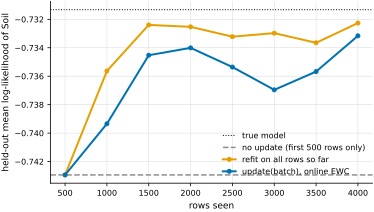

In [7]:
seen = 500 * np.arange(1, len(small) + 1)
fig, ax = plt.subplots(figsize=(0.75 * DOUBLE, 3))
ax.axhline(true_ll, color=INK, lw=1, ls=":", label="true model")
ax.axhline(frozen_ll, color=GREY, lw=1.5, ls="--", label="no update (first 500 rows only)")
ax.plot(seen, refit_ll, "o-", color=ORANGE, lw=2, ms=4, label="refit on all rows so far")
ax.plot(seen, ewc_ll, "o-", color=BLUE, lw=2, ms=4, label="update(batch), online EWC")
ax.set(xlabel="rows seen", ylabel="held-out mean log-likelihood of Soil",
       )
ax.legend(frameon=False, fontsize=8, loc="lower right")
save(fig, "05_fig2")      # vector PDF + 300-dpi PNG in examples/figures/
plt.show()

**Figure.** Held-out mean log-likelihood of the `Soil` MDN as rows arrive: `update(batch)` with online EWC (blue) and a refit on all rows so far (orange); dotted: the true model; dashed grey: the model that saw only the first 500 rows. One run.

After 4000 rows the updated MDN scores -0.7332, close to the refit (-0.7323)
and to the true model (-0.7313), and well above the model that saw only the
first 500 rows (-0.7429).  The update is not exact: between 1000 and 3500 rows
it stays below the refit, by up to about 0.004 nats.  It is cheaper: on
average an update takes about a quarter of the time of a refit or less, and
the refit's cost keeps growing with the rows seen (printed above).

## 3. A failed update changes nothing

`update` checks what it can before touching any mechanism: a missing column,
an unfitted node, NaN or infinite values.  Such a batch is refused up front.

In [8]:
nan_batch = sample(200)
nan_batch["Growth"][3] = float("nan")
try:
    streamed.update(nan_batch)
except ValueError as err:
    print("refused before any change:", err)

refused before any change: update() data contains NaN or infinite values in column(s) ['Growth']; drop or impute those rows first.


Other problems show up only while a node is being updated.  Here row 150 has
`WetGrass = 2`, outside the declared 2 states.  Nodes are updated in
topological order, so `Rain` and `Sprinkler` are already updated when
`WetGrass` raises.  By default (`atomic=True`) every mechanism is copied before
it is touched and restored on failure, so the model is exactly as it was:
same parameters, same answers.

In [9]:
bad_batch = sample(200)
bad_batch["WetGrass"][150] = 2
before = copy.deepcopy(streamed.state_dict())
probe = sample(1000)
with torch.no_grad():
    lp_before = streamed.log_prob(probe)
try:
    streamed.update(bad_batch)
except ValueError as err:
    print("update failed:", err)
with torch.no_grad():
    lp_after = streamed.log_prob(probe)
same_state = all(torch.equal(v, before[k]) for k, v in streamed.state_dict().items())
print("every parameter and buffer bit-identical:", same_state)
print("log_prob of 1000 rows bit-identical:     ", bool(torch.equal(lp_before, lp_after)))

update failed: update data has class/parent index beyond the declared cardinality the CPT was fit with
every parameter and buffer bit-identical: True
log_prob of 1000 rows bit-identical:      True


With `atomic=False` nothing is copied, and the same failure leaves the model
half updated:

In [10]:
half = copy.deepcopy(streamed)
try:
    half.update(bad_batch, atomic=False)
except ValueError:
    pass
changed = sorted({k.split(".")[1] for k, v in half.state_dict().items() if not torch.equal(v, before[k])})
print("nodes changed by the failed non-atomic update:", changed)

nodes changed by the failed non-atomic update: ['Rain', 'Sprinkler']


## 4. A change of regime: `forgetting`

After 10 batches of 500 rows the world changes: on dry days the sprinkler is
now used with probability 0.1 instead of 0.5, and the slope of `Growth` on
`Soil` drops from 0.8 to 0.3.  We keep updating with the new data.

`update(batch, forgetting=f)` multiplies the stored statistics by `f` before
adding the new batch, so old data fade geometrically (`f = 1` keeps them all).
We compare `f = 1`, `0.9` and `0.7`, and score each model with the exact KL to
the regime in force.

In [11]:
OLD = dict(p_sprinkler=P_SPRINKLER, slope=0.8)
NEW = dict(p_sprinkler=torch.tensor([[0.9, 0.1], [0.9, 0.1]]), slope=0.3)
seed_all(6)
stream = [sample(500, **(OLD if i < 10 else NEW)) for i in range(30)]
truth = [OLD if i < 10 else NEW for i in range(30)]


def tracked(model) -> tuple:
    with torch.no_grad():
        p_spr = float(model.mechanisms["Sprinkler"](torch.tensor([[0]], device=model.device)).probs[0, 1])
        g = model.mechanisms["Growth"](torch.tensor([[0.0], [1.0]], device=model.device)).mean
    return p_spr, float(g[1, 0] - g[0, 0])


drift = {}
for f in (1.0, 0.9, 0.7):
    model = build()
    model.fit(stream[0])
    out = {"p_spr": [], "slope": [], "kl": []}
    for i in range(30):
        if i > 0:
            model.update(stream[i], forgetting=f)
        p_spr, slope = tracked(model)
        out["p_spr"].append(p_spr)
        out["slope"].append(slope)
        out["kl"].append(exact_kl(model, **truth[i]))
    drift[f] = out
for f, out in drift.items():
    print(f"forgetting={f}: KL before the change {out['kl'][9]:.4f}, 5 batches after {out['kl'][14]:.4f},"
          f" 20 batches after {out['kl'][29]:.4f};  final P(Sprinkler=1 | dry) {out['p_spr'][-1]:.3f},"
          f" slope {out['slope'][-1]:.3f}")

forgetting=1.0: KL before the change 0.0015, 5 batches after 0.7475, 20 batches after 0.2900;  final P(Sprinkler=1 | dry) 0.222, slope 0.480
forgetting=0.9: KL before the change 0.0015, 5 batches after 0.4677, 20 batches after 0.0406;  final P(Sprinkler=1 | dry) 0.126, slope 0.344
forgetting=0.7: KL before the change 0.0021, 5 batches after 0.1208, 20 batches after 0.0030;  final P(Sprinkler=1 | dry) 0.096, slope 0.292


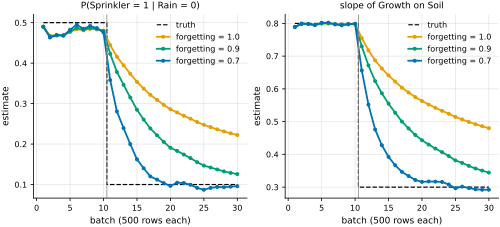

In [12]:
batch_axis = np.arange(1, 31)
colors = {1.0: ORANGE, 0.9: AQUA, 0.7: BLUE}
fig, (ax_p, ax_s) = plt.subplots(1, 2, figsize=(DOUBLE, 3.2))
for ax, key, true_old, true_new, label in (
        (ax_p, "p_spr", 0.5, 0.1, "P(Sprinkler = 1 | Rain = 0)"),
        (ax_s, "slope", 0.8, 0.3, "slope of Growth on Soil")):
    ax.step(batch_axis, [true_old if i < 10 else true_new for i in range(30)], where="mid",
            color=INK, lw=1.2, ls="--", label="truth")
    for f, out in drift.items():
        ax.plot(batch_axis, out[key], "o-", color=colors[f], lw=1.8, ms=3, label=f"forgetting = {f}")
    ax.axvline(10.5, color=GREY, lw=0.8)
    ax.set(xlabel="batch (500 rows each)", ylabel="estimate", title=label)
    ax.legend(frameon=False, fontsize=8, loc="upper right")
save(fig, "05_fig3")      # vector PDF + 300-dpi PNG in examples/figures/
plt.show()

**Figure.** Estimates of one table entry (left) and of one regression slope (right) after each batch of 500 rows, for three forgetting factors; the truth (dashed) changes after batch 10. One run per factor.

With `forgetting = 1` every row counts the same, so after the change the
estimates move slowly toward the new truth: 20 batches later the slope is
still 0.480 (truth 0.3) and the KL is 0.290.  With `0.9` the final slope is
0.344 (KL 0.041).  With `0.7` the model reaches the new regime in about 10
batches (final slope 0.292, KL 0.0030).  The price of forgetting is noise: a
model that forgets fast relies on fewer rows, so before the change its KL is
higher (0.0021 against 0.0015).